# Electride discovery with a reasoning swarm

Open this notebook from the repository folder in Jupyter with a Python 3.11+ kernel, then choose **Run All**. The first cell installs dependencies. Section 1 asks you to choose your LLM provider and enter your API key in a masked field; the remaining cells run automatically.

The sample dataset, feature catalog, configuration, and local papers are included. Settings: `config.yaml`. Code: `src/agent.py` (schemas, prompts, swarm loop), `src/tools.py` (web, calculator, arXiv, local RAG), and `src/evaluator.py` (deterministic evaluation). Add extra PDFs to `inputs/kb/` if desired.

In [1]:
%pip install -r src/requirements.txt

Note: you may need to restart the kernel to use updated packages.


## 1. Choose your LLM provider

Choose **OpenRouter**, **OpenAI**, or **Other / custom endpoint** below. OpenRouter and OpenAI have preset endpoints and models, so you only need your API key. For a custom endpoint, also enter its API base URL and model ID. It must support OpenAI-compatible Chat Completions with JSON mode and `max_tokens`.

Press Enter after each answer. Your key is masked and is not written into the notebook source or outputs. No environment variables or code edits are required.

In [ ]:
import functools
from getpass import getpass

import instructor
from openai import AsyncOpenAI

print("Choose your LLM provider:")
print("  1. OpenRouter")
print("  2. OpenAI")
print("  3. Other / custom endpoint (OpenAI-compatible)")
choice = input("Provider [1–3]: ").strip()
while choice not in {"1", "2", "3"}:
    choice = input("Please enter 1, 2, or 3: ").strip()

presets = {
    "1": ("OpenRouter", "https://openrouter.ai/api/v1", "openai/gpt-oss-120b"),
    "2": ("OpenAI", "https://api.openai.com/v1", "gpt-5.6-terra"),
}
if choice in presets:
    provider, base_url, MODEL_NAME = presets[choice]
else:
    provider = "Custom endpoint"
    base_url = input("API base URL: ").strip()
    MODEL_NAME = input("Model name: ").strip()
    while not base_url or not MODEL_NAME:
        print("The custom option needs both an API URL and a model name.")
        base_url = input("API base URL: ").strip()
        MODEL_NAME = input("Model name: ").strip()

print(f"\n{provider} · {MODEL_NAME}")
_api_key = getpass("API key: ").strip()
while not _api_key:
    _api_key = getpass("Please enter your API key: ").strip()
client = AsyncOpenAI(base_url=base_url, api_key=_api_key)
del _api_key
async_gen = instructor.from_openai(client, mode=instructor.Mode.JSON)

# Preserve OpenRouter's sampling settings; other providers use their defaults.
TEMPERATURE = 0.7 if choice == "1" else None
call_settings = {"max_retries": 3}
if choice == "2":
    call_settings["max_completion_tokens"] = 8192
else:
    call_settings["max_tokens"] = 8192
if TEMPERATURE is not None:
    call_settings["temperature"] = TEMPERATURE
_create = functools.partial(async_gen.chat.completions.create, **call_settings)
N_TRIES = 5

async def _create_with_retry(**kwargs):
    for attempt in range(N_TRIES):
        try:
            call_kwargs = dict(kwargs)
            if attempt and TEMPERATURE is not None:
                call_kwargs["temperature"] = max(0.1, TEMPERATURE - 0.15 * attempt)
            return await _create(**call_kwargs)
        except Exception as exc:
            if attempt == N_TRIES - 1:
                raise
            print(f"LLM call failed (attempt {attempt + 1}/{N_TRIES}: {type(exc).__name__}); retrying")

async_gen.chat.completions.create = _create_with_retry
print("Setup complete. Continue with the swarm below.")

## 2. Config

In [4]:
%load_ext autoreload
%autoreload 2

import sys; sys.path.insert(0, "src")
from agent import Swarm, load_config
from evaluator import score_dataset

CONFIG = load_config("config.yaml")

W1022 17:30:57.970000 70957 site-packages/torch/distributed/elastic/multiprocessing/redirects.py:35] NOTE: Redirects are currently not supported in MacOs.


## 3. Build the swarm

Uses the LLM from section 1; loads the embedding model, the feature data + evaluator, and the tools (builds the local paper index).

Loading weights:   0%|          | 0/103 [00:00<?, ?it/s]

200 labeled structures (84 electrides), all used for evaluation; 26 of 49 catalog features usable; each proposal scored on 5 deterministic 60%/40% train/validation splits, stratified by class: every split trains on 50 electrides + 70 non-electrides and validates on 34 + 46
KB index: 227 chunks from 3 files in /Users/z8i/Desktop/LLM Hackathon/Github/ElectrideDetectives/inputs/kb
Discover an interpretable, physics-informed descriptor set that identifies electrides.
Electrides are ionic compounds in which some valence electrons are not bound to any atom but occupy
interstitial cavities, channels or layers and act as anions (anionic electrons). Using ONLY the precomputed
structural and chemical features of the labeled structures (catalog in the system prompt), find the set of features
whose combination separates electrides from non-electrides. Justify every selected feature physically, supported by
literature where possible. A model is fitted on your features and evaluated deterministicall

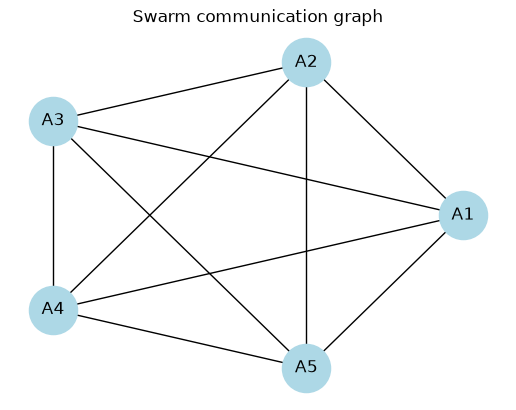

In [5]:
swarm = Swarm(CONFIG, llm=async_gen, model_name=MODEL_NAME)
swarm.plot_graph()

## 4. Run

Every round each agent may use one tool, then returns a `proposal` (the feature set its model should use). A gradient-boosting classifier is fitted on exactly those features and evaluated on all labeled structures over repeated stratified splits; the evaluation opens its next round. After the last round the top-ranked feature set is refit on all structures and the model is saved to `outputs/final_model_*.joblib`.

Run log: outputs/log_run_2026-10-22_173111.jsonl

==================== ROUND 1/5 ====================
finished: A4 A2 A1 A3 A5 


Agent,Peers,Tool,Evidence,Feature set,Share of the model's decisions,F1,ROC-AUC,Electrides found / non-electrides rejected,Notes,Tokens in / out
A1,-,"literature_search ""electride interstitial electron descriptors""",Literature search FAILED (not an empty result) - error: arXiv request timed out after 50s. The arXiv API may be slow or overloaded. Please retry shortly.,alkali_alkaline_site_fraction pauling_electronegativity__mean volume_per_atom_A3 max_clearance_A sampled_grid_clearance_statistics_A__max candidate_count_before_output_limit neutral_assignment_exists metal_site_fraction,pauling_electronegativity__mean 49% candidate_count_before_output_limit 12% metal_site_fraction 10% alkali_alkaline_site_fraction 9% volume_per_atom_A3 9% max_clearance_A 6% sampled_grid_clearance_statistics_A__max 5% neutral_assignment_exists 1%,0.82 ± 0.04,0.92 ± 0.03,0.82 / 0.87,-,"11,937 / 1,955"
A2,-,"literature_search ""electride interstitial electrons descriptors""",Literature search FAILED (not an empty result) - error: arXiv request timed out after 50s. The arXiv API may be slow or overloaded. Please retry shortly.,alkali_alkaline_site_fraction pauling_electronegativity__min max_clearance_A sampled_grid_clearance_statistics_A__max neutral_assignment_exists volume_per_atom_A3 metal_site_fraction candidate_count_before_output_limit,metal_site_fraction 22% volume_per_atom_A3 20% candidate_count_before_output_limit 19% pauling_electronegativity__min 15% alkali_alkaline_site_fraction 10% max_clearance_A 7% sampled_grid_clearance_statistics_A__max 5% neutral_assignment_exists 1%,0.77 ± 0.06,0.90 ± 0.04,0.79 / 0.81,-,"7,965 / 1,592"
A3,-,"literature_search ""electride descriptor screening""",1812.06222 (2018): Discovering Inorganic Electrides from an Automated Computational Scree 2605.11724 (2026): Theory and Discovery of Electrides 1901.05121 (2019): Discovery of Hidden Classes of Layered Electrides by Extensive High-th,alkali_alkaline_site_fraction pauling_electronegativity__min sampled_grid_clearance_statistics_A__max sampled_grid_clearance_statistics_A__mean total_assignment_count neutral_assignment_exists,sampled_grid_clearance_statistics_A__mean 39% total_assignment_count 19% sampled_grid_clearance_statistics_A__max 15% alkali_alkaline_site_fraction 14% pauling_electronegativity__min 11% neutral_assignment_exists 2%,0.82 ± 0.05,0.91 ± 0.03,0.85 / 0.83,-,"12,725 / 2,070"
A4,-,"literature_search ""electride descriptor high-throughput screening""",Literature search FAILED (not an empty result) - rate_limited: arXiv is rate limiting this IP (HTTP 429). Please wait 60 seconds before retrying.,pauling_electronegativity__min alkali_alkaline_site_fraction max_clearance_A sampled_grid_clearance_statistics_A__mean neutral_assignment_exists total_assignment_count volume_per_atom_A3 metal_site_fraction,sampled_grid_clearance_statistics_A__mean 31% volume_per_atom_A3 18% total_assignment_count 18% metal_site_fraction 10% alkali_alkaline_site_fraction 8% max_clearance_A 8% pauling_electronegativity__min 6% neutral_assignment_exists 1%,0.81 ± 0.04,0.92 ± 0.03,0.85 / 0.82,-,"8,011 / 1,777"
A5,-,"literature_search ""electride excess electrons cavity clearance descriptor""",Literature search FAILED (not an empty result) - error: arXiv request timed out after 50s. The arXiv API may be slow or overloaded. Please retry shortly.,neutral_assignment_exists alkali_alkaline_site_fraction pauling_electronegativity__min max_clearance_A sampled_grid_clearance_statistics_A__max sampled_grid_clearance_statistics_A__mean,sampled_grid_clearance_statistics_A__mean 42% alkali_alkaline_site_fraction 16% max_clearance_A 14% sampled_grid_clearance_statistics_A__max 13% pauling_electronegativity__min 13% neutral_assignment_exists 2%,0.80 ± 0.02,0.91 ± 0.03,0.82 / 0.84,chose no tool; asked to gather evidence,"17,222 / 4,133"


Agent,Answer,Next step,Suggested new features
A1,"Electrides are ionic solids where excess valence electrons reside in interstitial cavities and act as anions. The key physical ingredients are (i) strongly electropositive cations that provide a low‑electronegativity environment, (ii) a crystal lattice that contains sufficiently large voids or channels to accommodate an electron, and (iii) an oxidation‑state imbalance so that the formal charge cannot be neutralized without invoking interstitial ...","After the deterministic evaluation of this feature set is returned, I will examine which descriptors contribute most to the ROC‑AUC and whether any class (e.g., low‑volume electrides) is still mis‑classified. Based on that feedback I may replace or","• Electron localization function (ELF) maximum in interstitial regions – would directly quantify anionic electron density. • Void connectivity dimensionality (0D/1D/2D) – distinguishes cavity, channel, and layer electrides. • Bader charge on identified void centers – provides a charge‑based measure of electron localization."
A2,"The literature search failed to return usable evidence, so I rely on established electride criteria from prior knowledge: (i) presence of highly electropositive cations (alkali/alkaline‑earth metals), (ii) low minimum electronegativity, (iii) large interstitial voids that can host anionic electrons, and (iv) the inability to assign a charge‑balanced oxidation state (excess electrons). These physical considerations guide the first descriptor set.","After the deterministic evaluation of this feature set, I will examine which features contribute most to the ROC‑AUC and adjust the set accordingly—e.g., replace redundant volume‑based descriptors with more direct void‑connectivity metrics if needed.","• Electron localization function (ELF) peak values in interstitial regions to directly quantify anionic electron density. • Void connectivity metrics (e.g., dimensionality of percolating void network) to differentiate 0D, 1D, and 2D electride topologies. • Calculated work function or band gap to capture the metallic/semimetallic character typical of many electrides."
A3,"The literature on high‑throughput electride discovery highlights three physical ingredients that separate electrides from conventional solids: (i) a strongly electropositive chemical environment (high fraction of alkali/alkaline‑earth metals and low minimum Pauling electronegativity), (ii) the presence of oversized interstitial voids that can host anionic electrons (large sampled‑grid clearance statistics), and (iii) an excess of valence electron ...","Await the deterministic evaluation of this six‑feature set on the 200‑structure benchmark. Based on the ROC‑AUC and the error analysis (e.g., which class of electrides is still mis‑classified), I will consider adding a volume‑per‑atom descriptor or","• ELF_max_in_voids – maximum electron localization function value within identified void regions to directly capture interstitial electron density. • Bader_charge_void – Bader charge integrated over void sites, quantifying anionic electron population. • void_connectivity_dimensionality – categorical descriptor (0D, 1D, 2D) of the void network to capture channel vs cavity behavior."
A4,"The literature search for electride descriptor studies failed due to rate limiting, so I must rely on established domain knowledge. Electrides are characterized by (i) highly electropositive cations (low Pauling electronegativity, high alkali/alkaline‑earth fraction), (ii) large interstitial voids that can host anionic electrons (large cavity clearances), and (iii) an excess of valence electrons that cannot be assigned to a charge‑balanced oxidat ...","After the deterministic evaluation of this feature set, I will examine which features contribute most to the ROC‑AUC and whether any are redundant. If performance is insufficient, I will consider replacing or augmenting features (e.g., using sampled_","• Electron localization fun

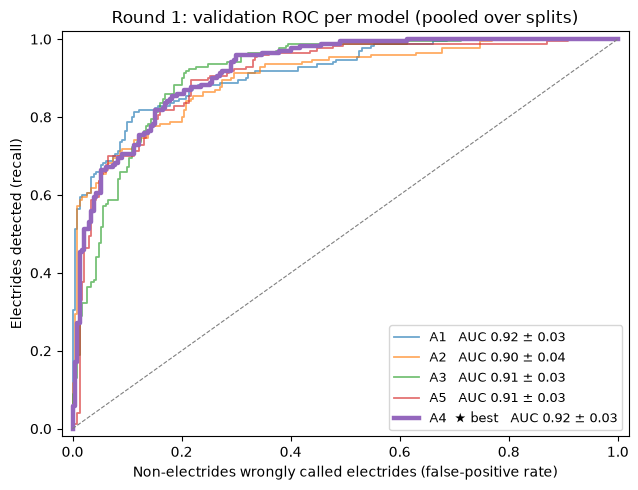

Best feature set in round 1: A4 | ROC-AUC 0.92 ± 0.03 | F1 0.81 ± 0.04 | sampled_grid_clearance_statistics_A__mean  31%, volume_per_atom_A3  18%, total_assignment_count  18%, metal_site_fraction  10%, alkali_alkaline_site_fraction  8%, max_clearance_A  8%, pauling_electronegativity__min  6%, neutral_assignment_exists  1%

==================== ROUND 2/5 ====================
finished: A5 A3 A4 A2 A1 


Agent,Peers,Tool,Evidence,Feature set,Share of the model's decisions,F1,ROC-AUC,Electrides found / non-electrides rejected,Notes,Tokens in / out
A1,"A2, A5","literature_search ""electride transition metal oxidation state space group""",Literature search FAILED (not an empty result) - error: arXiv request timed out after 50s. The arXiv API may be slow or overloaded. Please retry shortly.,pauling_electronegativity__mean metal_site_fraction transition_metal_site_fraction sampled_grid_clearance_statistics_A__mean sampled_grid_clearance_statistics_A__std total_assignment_count space_group__number pauling_electronegativity__std,pauling_electronegativity__mean 42% space_group__number 14% sampled_grid_clearance_statistics_A__mean 14% pauling_electronegativity__std 13% total_assignment_count 6% sampled_grid_clearance_statistics_A__std 5% metal_site_fraction 3% transition_metal_site_fraction 3%,0.85 ± 0.04,0.95 ± 0.02,0.85 / 0.89,chose no tool; asked to gather evidence improved vs parent #3 (+0.035),"29,352 / 5,004"
A2,"A1, A4","literature_search ""electride oxidation state imbalance descriptor""",2605.11724 (2026): Theory and Discovery of Electrides 2411.12170 (2024): Layered semiconducting electrides in p-block metal oxides 2508.04548 (2025): Using Topology to Predict Electrides in the Solid State,alkali_alkaline_site_fraction metal_site_fraction pauling_electronegativity__min pauling_electronegativity__mean sampled_grid_clearance_statistics_A__mean sampled_grid_clearance_statistics_A__std candidate_count_before_output_limit total_assignment_count,pauling_electronegativity__mean 43% sampled_grid_clearance_statistics_A__mean 19% total_assignment_count 11% candidate_count_before_output_limit 7% sampled_grid_clearance_statistics_A__std 7% alkali_alkaline_site_fraction 6% metal_site_fraction 5% pauling_electronegativity__min 3%,0.85 ± 0.04,0.94 ± 0.03,0.85 / 0.88,chose no tool; asked to gather evidence improved vs parent #2 (+0.038),"30,762 / 5,336"
A3,"A1, A5","literature_search ""electride volume per atom descriptor""",2605.11724 (2026): Theory and Discovery of Electrides 2512.24989 (2025): Best Practices for Modelling Electrides 2104.13151 (2021): Prediction of anomalous LA-TA splitting in electrides,alkali_alkaline_site_fraction pauling_electronegativity__min total_assignment_count max_clearance_A volume_per_atom_A3 candidate_count_before_output_limit sampled_grid_clearance_statistics_A__max,volume_per_atom_A3 25% pauling_electronegativity__min 19% candidate_count_before_output_limit 18% total_assignment_count 12% alkali_alkaline_site_fraction 10% max_clearance_A 9% sampled_grid_clearance_statistics_A__max 7%,0.75 ± 0.05,0.86 ± 0.03,0.81 / 0.75,chose no tool; asked to gather evidence worse vs parent #4 (-0.052),"32,971 / 4,537"
A4,"A5, A1","kb_search ""[arXiv:2605.11724] void candidate count""",arXiv:2605.11724 (score 0.231) arXiv:2605.11724 (score 0.207) arXiv:2605.11724 (score 0.175) arXiv:2605.11724 (score 0.149),pauling_electronegativity__mean alkali_alkaline_site_fraction metal_site_fraction volume_per_atom_A3 sampled_grid_clearance_statistics_A__mean sampled_grid_clearance_statistics_A__max total_assignment_count candidate_count_before_output_limit,pauling_electronegativity__mean 41% sampled_grid_clearance_statistics_A__mean 19% total_assignment_count 11% volume_per_atom_A3 7% sampled_grid_clearance_statistics_A__max 7% candidate_count_before_output_limit 6% alkali_alkaline_site_fraction 5% metal_site_fraction 4%,0.84 ± 0.04,0.93 ± 0.03,0.86 / 0.86,chose no tool; asked to gather evidence improved vs parent #1 (+0.010),"31,167 / 5,286"
A5,"A1, A4","kb_search ""[arXiv:2605.11724] candidate void centers electride""",arXiv:2605.11724 (score 0.406) arXiv:2605.11724 (score 0.377) arXiv:2605.11724 (score 0.324) arXiv:2605.11724 (score 0.316),alkali_alkaline_site_fraction pauling_electronegativity__min sampled_grid_clearance_statistics_A__mean volume_per_atom_A3 candidate_count_before_output_limit metal_site_fraction,sampled_grid_cleara

Agent,Answer,Next step,Suggested new features
A1,"The literature search for ""electride transition metal oxidation state space group"" failed to return any usable references, so no new external evidence could be incorporated. Consequently the revision relies on the quantitative feedback from the previous evaluation and on established electride principles. The earlier model showed that mean Pauling electronegativity, overall metal fraction, and transition‑metal fraction are the most informative c ...","Await the deterministic evaluation of this revised feature set. Based on the new ROC‑AUC and feature‑importance scores I will assess whether additional descriptors (e.g., ELF peaks or void‑connectivity dimensionality) are required, or whether any re","• Electron localization function (ELF) peak in interstitial regions – directly quantifies anionic electron density. • Void connectivity dimensionality (0D/1D/2D) – captures whether voids form isolated cavities, channels, or layers."
A2,"The paper *Theory and Discovery of Electrides* (arXiv:2605.11724) explicitly proposes a set of high‑throughput descriptors for electride identification: (i) the presence of highly electropositive cations, (ii) large and heterogeneous interstitial voids, and (iii) an ambiguous oxidation‑state landscape that signals excess electrons. This aligns with the three pillars identified in earlier work and explains why my original clearance features (max_c ...","After the deterministic evaluation of this revised set I will examine whether the added mean/std clearance and total_assignment_count raise the ROC‑AUC. If mis‑classifications persist for structures with many small voids, I will consider adding a con",• Electron localization function (ELF) maxima in identified void regions to directly quantify anionic electron density. • Void‑network dimensionality (0D/1D/2D) derived from a graph of void centers. • Average distance between void centers and nearest electropositive cation to assess stabilization of interstitial electrons.
A3,"The new literature confirms that high‑throughput electride screening relies on (i) electropositive chemistry, (ii) descriptors of large interstitial space, and (iii) oxidation‑state ambiguity. Xiao et al. (2026) explicitly develop clearance‑based descriptors (e.g., max_clearance_A) as key predictors of interstitial electron stability, while Burton (2025) notes that overall structural openness (e.g., larger volume per atom) correlates with electr ...","Await the deterministic evaluation of the revised seven‑feature set. Based on the new ROC‑AUC and feature‑importance diagnostics, consider whether additional global geometry descriptors (e.g., cell_condition_number) or a derived clearance‑to‑volume","• ELF_max_in_voids – maximum electron localization function value within identified void regions to directly quantify interstitial electron density. • Bader_charge_void – integrated Bader charge on void sites, providing a charge‑based measure of anionic electrons. • void_connectivity_dimensionality – categorical descriptor (0D, 1D, 2D) of the void network topology."
A4,"The screening study in arXiv:2605.11724 describes an electride descriptor that begins with a Bader analysis of the electron localization function (ELF) to locate interstitial ELF maxima and then evaluates a ""figure of merit"" Zₑ based on the ELF basin charge. Although ELF‑based quantities are not present in the precomputed catalog, the same workflow first generates a set of candidate interstitial sites (void‑center candidates) before any output li ...","Run the deterministic evaluation of this revised feature set to measure ROC‑AUC and feature importance. If performance improves, consider further refinements such as replacing `pauling_electronegativity__mean` with a weighted electronegativity that a","• Electron localization function (ELF) maximum in interstitial regions – would directly measure anionic electron density. • Void connectivity dimensionality (0D/1D/2D) – dist

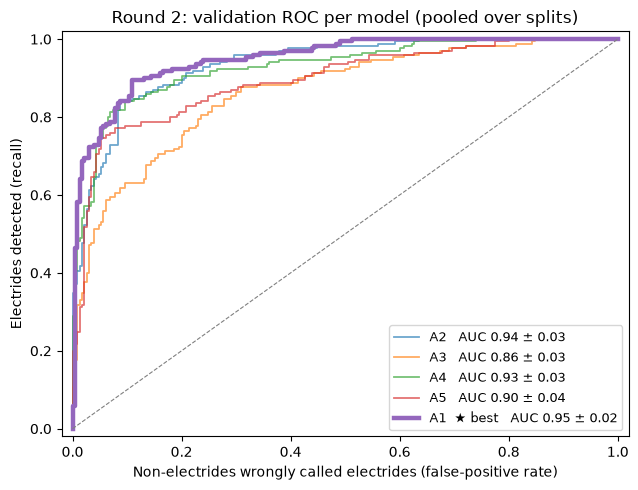

Best feature set in round 2: A1 | ROC-AUC 0.95 ± 0.02 | F1 0.85 ± 0.04 | pauling_electronegativity__mean  42%, space_group__number  14%, sampled_grid_clearance_statistics_A__mean  14%, pauling_electronegativity__std  13%, total_assignment_count  6%, sampled_grid_clearance_statistics_A__std  5%, metal_site_fraction  3%, transition_metal_site_fraction  3%

==================== ROUND 3/5 ====================
finished: A1 A4 A2 A3 A5 


Agent,Peers,Tool,Evidence,Feature set,Share of the model's decisions,F1,ROC-AUC,Electrides found / non-electrides rejected,Notes,Tokens in / out
A1,"A4, A5","literature_search ""electride ELF candidate count""",2510.01583 (2025): Electride behavior at high pressure in silicon and other elements in s 2605.11724 (2026): Theory and Discovery of Electrides 1801.02948 (2018): High-Throughput Identification of Electrides from all Known Inorganic,pauling_electronegativity__mean pauling_electronegativity__std alkali_alkaline_site_fraction f_block_site_fraction sampled_grid_clearance_statistics_A__mean sampled_grid_clearance_statistics_A__max candidate_count_before_output_limit volume_per_atom_A3,pauling_electronegativity__mean 42% sampled_grid_clearance_statistics_A__mean 17% pauling_electronegativity__std 16% volume_per_atom_A3 8% sampled_grid_clearance_statistics_A__max 6% candidate_count_before_output_limit 5% alkali_alkaline_site_fraction 4% f_block_site_fraction 1%,0.87 ± 0.06,0.94 ± 0.03,0.87 / 0.90,chose no tool; asked to gather evidence worse vs parent #10 (-0.016),"51,644 / 5,497"
A2,"A4, A1","literature_search ""electride transition metal""",2106.00921 (2021): Anomalous diamagnetism of electride electrons in transition metal sili 2411.12170 (2024): Layered semiconducting electrides in p-block metal oxides 1811.01169 (2018): Superconductivity in Li6P electride,pauling_electronegativity__mean alkali_alkaline_site_fraction transition_metal_site_fraction sampled_grid_clearance_statistics_A__mean volume_per_atom_A3 total_assignment_count space_group__number pauling_electronegativity__std,pauling_electronegativity__mean 40% space_group__number 14% pauling_electronegativity__std 14% sampled_grid_clearance_statistics_A__mean 13% volume_per_atom_A3 7% total_assignment_count 6% alkali_alkaline_site_fraction 3% transition_metal_site_fraction 2%,0.88 ± 0.03,0.95 ± 0.01,0.88 / 0.91,chose no tool; asked to gather evidence improved vs parent #9 (+0.010),"54,009 / 5,241"
A3,"A5, A1","literature_search ""electride space group symmetry""",2409.17249 (2024): Semiconducting Electrides Derived From Sodalite: A First-principles St 2605.11724 (2026): Theory and Discovery of Electrides 2302.06999 (2023): Superconductivity in Li8Au electride,pauling_electronegativity__min total_assignment_count sampled_grid_clearance_statistics_A__mean volume_per_atom_A3 candidate_count_before_output_limit metal_site_fraction transition_metal_site_fraction space_group__number,sampled_grid_clearance_statistics_A__mean 24% total_assignment_count 17% space_group__number 16% volume_per_atom_A3 15% metal_site_fraction 13% pauling_electronegativity__min 6% candidate_count_before_output_limit 6% transition_metal_site_fraction 3%,0.80 ± 0.03,0.91 ± 0.02,0.85 / 0.79,chose no tool; asked to gather evidence no clear change vs parent #4 (-0.005),"54,735 / 5,139"
A4,"A1, A3","literature_search ""electride space group descriptor""","2605.11724 (2026): Theory and Discovery of Electrides 2508.04548 (2025): Using Topology to Predict Electrides in the Solid State 1606.01174 (2016): Semimetallic ""Electride Bands"" Derived from Interlayer Electrons in Qu",pauling_electronegativity__mean pauling_electronegativity__std sampled_grid_clearance_statistics_A__mean max_clearance_A total_assignment_count space_group__number transition_metal_site_fraction,pauling_electronegativity__mean 43% space_group__number 14% sampled_grid_clearance_statistics_A__mean 14% pauling_electronegativity__std 14% max_clearance_A 7% total_assignment_count 6% transition_metal_site_fraction 2%,0.89 ± 0.03,0.96 ± 0.01,0.88 / 0.93,chose no tool; asked to gather evidence improved vs parent #8 (+0.029),"54,342 / 5,097"
A5,"A1, A3","literature_search ""electride oxidation state excess descriptor""",2411.12170 (2024): Layered semiconducting electrides in p-block metal oxides 2605.11724 (2026): Theory and Discovery of Electrides 2508.04548 (2025): Using Topology to Predict Electrides in the Solid State,pauling_electronegat

Agent,Answer,Next step,Suggested new features
A1,"The literature returned three relevant arXiv papers. The 2026 work (arXiv:2605.11724) explicitly states that their high‑throughput electride descriptor starts from a Bader analysis of the ELF, counting ELF maxima (interstitial basins) and using a figure‑of‑merit Z_e. Because the pre‑computed catalog lacks ELF values, the scalar feature `cavity_geometry.candidate_count_before_output_limit` – the number of void‑center candidates before truncation ...","Submit the revised eight‑feature set for deterministic evaluation. If ROC‑AUC improves, analyse the feature‑importance scores; if any geometry descriptor remains weak, consider swapping `sampled_grid_clearance_statistics_A__max` for `sampled_grid_cl","• Electron localization function (ELF) maximum in interstitial regions – would directly measure anionic electron density. • Void connectivity dimensionality (0D/1D/2D) – captures whether voids form isolated cavities, channels, or layers."
A2,"The literature search returned a paper (arXiv:2106.00921) reporting electride behavior in transition‑metal silicides (LaScSi, Y5Si3). This demonstrates that transition‑metal cations can provide the electropositive environment needed to stabilize interstitial anionic electrons, supporting the inclusion of a transition‑metal site fraction descriptor. The same study also notes that the electride electrons occupy hollow interstitial positions, confir ...","Run the deterministic evaluation of the revised eight‑feature set to see whether ROC‑AUC improves beyond 0.94. If performance plateaus, I will consider adding an interaction term (e.g., alkali_alkaline_site_fraction × pauling_electronegativity__mean)","• Electron localization function (ELF) maximum in identified void regions – direct quantification of anionic electron density. • Void‑network dimensionality (0D/1D/2D) derived from a graph of void centers – distinguishes cavity, channel, and layer electrides."
A3,"The recent literature (Liu et al., 2024) reports that a specific high‑symmetry space group (I‑43m) stabilizes electron localization in sodalite cages and emphasizes that low surrounding cation electronegativity drives electride formation. This directly supports adding a symmetry descriptor (space_group__number) and reinforces the importance of the minimum Pauling electronegativity. The evaluation of my earlier sets shows that (i) the minimum ele ...","Submit the revised eight‑feature set for deterministic evaluation. Depending on the resulting ROC‑AUC and feature‑importance analysis, I may consider replacing transition_metal_site_fraction with pauling_electronegativity__std or adding a derived cl","• ELF_max_in_voids – maximum electron‑localization‑function value within identified void regions to directly quantify anionic electron confinement. • Bader_charge_void – integrated Bader charge on void basins, providing a charge‑based measure of interstitial electrons. • void_connectivity_dimensionality – categorical descriptor (0D, 1D, 2D) of the void network topology."
A4,"The literature (arXiv:2605.11724) emphasizes that high‑throughput electride screening benefits from descriptors that capture (i) a strongly electropositive chemical environment, (ii) charge‑balance ambiguity, (iii) the presence of large interstitial voids, and (iv) crystallographic motifs (layered, channel or cage) that favour electron localization. The abstract confirms that space‑group symmetry is part of the descriptor set used to rank candida ...","Run the deterministic evaluation of the revised seven‑feature set to obtain ROC‑AUC and feature‑importance scores. If performance improves, consider testing interaction terms (e.g., clearance × space‑group) or a derived clearance‑to‑volume ratio to c","• ELF_max_in_voids – maximum electron localization function value within identified void regions to directly quantify anionic electron density. • Void_connectivity_dimensionality – categorical descriptor (0D, 1D, 2D) describing t

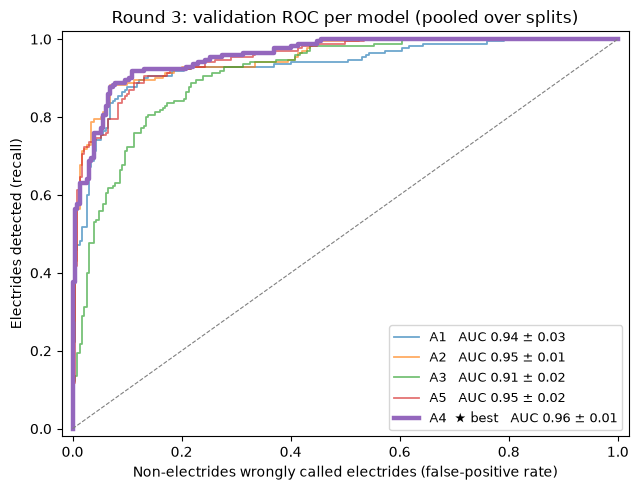

Best feature set in round 3: A4 | ROC-AUC 0.96 ± 0.01 | F1 0.89 ± 0.03 | pauling_electronegativity__mean  43%, space_group__number  14%, sampled_grid_clearance_statistics_A__mean  14%, pauling_electronegativity__std  14%, max_clearance_A  7%, total_assignment_count  6%, transition_metal_site_fraction  2%

==================== ROUND 4/5 ====================
finished: A1 A5 A2 A4 A3 


Agent,Peers,Tool,Evidence,Feature set,Share of the model's decisions,F1,ROC-AUC,Electrides found / non-electrides rejected,Notes,Tokens in / out
A1,"A2, A5",-,-,pauling_electronegativity__mean pauling_electronegativity__std sampled_grid_clearance_statistics_A__mean candidate_count_before_output_limit alkali_alkaline_site_fraction f_block_site_fraction volume_per_atom_A3 space_group__number,pauling_electronegativity__mean 40% space_group__number 15% pauling_electronegativity__std 15% sampled_grid_clearance_statistics_A__mean 13% volume_per_atom_A3 7% candidate_count_before_output_limit 5% alkali_alkaline_site_fraction 4% f_block_site_fraction 1%,0.89 ± 0.04,0.94 ± 0.02,0.89 / 0.91,worse vs parent #10 (-0.012),"24,640 / 1,862"
A2,"A1, A5",-,-,pauling_electronegativity__mean pauling_electronegativity__std sampled_grid_clearance_statistics_A__mean sampled_grid_clearance_statistics_A__max candidate_count_before_output_limit alkali_alkaline_site_fraction f_block_site_fraction metal_site_fraction,pauling_electronegativity__mean 43% sampled_grid_clearance_statistics_A__mean 17% pauling_electronegativity__std 16% sampled_grid_clearance_statistics_A__max 7% candidate_count_before_output_limit 7% alkali_alkaline_site_fraction 5% metal_site_fraction 3% f_block_site_fraction 2%,0.87 ± 0.05,0.95 ± 0.03,0.88 / 0.90,no clear change vs parent #13 (-0.003),"25,444 / 1,602"
A3,"A1, A2",-,-,pauling_electronegativity__mean pauling_electronegativity__std alkali_alkaline_site_fraction f_block_site_fraction sampled_grid_clearance_statistics_A__mean volume_per_atom_A3 total_assignment_count space_group__number,pauling_electronegativity__mean 40% space_group__number 15% pauling_electronegativity__std 14% sampled_grid_clearance_statistics_A__mean 13% volume_per_atom_A3 8% total_assignment_count 6% alkali_alkaline_site_fraction 3% f_block_site_fraction 1%,0.88 ± 0.03,0.95 ± 0.02,0.89 / 0.90,improved vs parent #4 (+0.036),"25,528 / 1,913"
A4,"A1, A2",-,-,pauling_electronegativity__mean pauling_electronegativity__std sampled_grid_clearance_statistics_A__mean sampled_grid_clearance_statistics_A__std candidate_count_before_output_limit f_block_site_fraction alkali_alkaline_site_fraction volume_per_atom_A3,pauling_electronegativity__mean 42% sampled_grid_clearance_statistics_A__mean 17% pauling_electronegativity__std 16% volume_per_atom_A3 8% candidate_count_before_output_limit 6% alkali_alkaline_site_fraction 5% sampled_grid_clearance_statistics_A__std 4% f_block_site_fraction 2%,0.85 ± 0.05,0.93 ± 0.03,0.86 / 0.87,worse vs parent #12 (-0.034),"25,399 / 1,838"
A5,"A2, A1",-,-,pauling_electronegativity__mean pauling_electronegativity__min alkali_alkaline_site_fraction f_block_site_fraction sampled_grid_clearance_statistics_A__mean max_clearance_A volume_per_atom_A3 candidate_count_before_output_limit,pauling_electronegativity__mean 43% sampled_grid_clearance_statistics_A__mean 18% max_clearance_A 11% alkali_alkaline_site_fraction 8% candidate_count_before_output_limit 6% volume_per_atom_A3 6% pauling_electronegativity__min 4% f_block_site_fraction 4%,0.83 ± 0.02,0.92 ± 0.04,0.81 / 0.89,worse vs parent #15 (-0.030),"24,607 / 1,869"


Agent,Answer,Next step,Suggested new features
A1,"The evaluation of the previous round showed that the features metal_site_fraction, transition_metal_site_fraction, sampled_grid_clearance_statistics_A__std, total_assignment_count and space_group__number contributed little to the model, while the electrochemical descriptors (mean electronegativity and its spread) and the geometric clearance mean were the strongest signals. Literature (arXiv:2605.11724) demonstrates that the number of void‑center ...","Submit this revised eight‑feature set for deterministic evaluation. If ROC‑AUC improves, examine feature‑importance; if any geometry descriptor remains weak, consider swapping volume_per_atom_A3 for sampled_grid_clearance_statistics_A__std or adding","• electron_localization_function_max: maximum ELF value within identified interstitial basins – would directly measure anionic electron density. • void_connectivity_dimensionality: categorical descriptor (0D/1D/2D) of the void network topology – distinguishes cavity, channel, and layer electrides."
A2,"The latest evaluation shows that the electropositivity descriptors (mean and std of Pauling electronegativity) and the average clearance are the strongest contributors, while alkali/alkaline fraction, transition‑metal fraction, volume per atom, total oxidation‑state count and space‑group number add little. To increase complementarity I replace the weak features with descriptors that (i) capture additional electropositive cation families (f‑block ...","Submit this revised feature set for deterministic evaluation to see whether ROC‑AUC improves beyond 0.95. If performance plateaus, I will explore interaction terms (e.g., alkali_alkaline_site_fraction × pauling_electronegativity__mean) or a derived r","• Electron localization function (ELF) maximum in identified void regions – would directly quantify anionic electron density. • Void‑network dimensionality (0D/1D/2D) – captures whether voids form isolated cavities, channels, or layers."
A3,"Recent high‑throughput electride studies (Xiao et al., 2026; Zhu et al., 2018; Liu et al., 2024; Burton, 2025) consistently identify three physical pillars: (i) a strongly electropositive chemical environment, (ii) an oxidation‑state imbalance that forces excess electrons into interstitial sites, and (iii) a spacious, heterogeneous void network that can host those electrons. The evaluation of earlier models shows that the most discriminating sca ...","Submit this eight‑feature set for deterministic evaluation. If the ROC‑AUC does not exceed ~0.95, consider swapping the f‑block fraction for the candidate_count_before_output_limit (as a direct ELF‑basin surrogate) or adding a derived clearance‑to‑v","• ELF_max_in_voids – maximum electron‑localization‑function value within identified void regions to directly quantify anionic electron confinement. • void_connectivity_dimensionality – categorical descriptor (0D, 1D, 2D) of the void network topology."
A4,"The evaluation of the previous set shows that the most discriminating descriptors are the average electronegativity, its heterogeneity, and the mean sampled‑grid clearance. Features that contributed little (max_clearance_A, total_assignment_count, space_group__number, transition_metal_site_fraction) can be replaced by descriptors that (i) directly proxy the ELF‑basin count used in the high‑throughput electride workflow (arXiv:2605.11724) and (ii) ...","Submit the new eight‑feature set for deterministic evaluation to see whether ROC‑AUC improves beyond 0.96. If performance plateaus, consider deriving a composite metric such as (candidate_count / volume_per_atom) to capture the density of voids per u","• ELF_max_in_voids – maximum electron localization function value within identified void regions (direct measure of anionic electron density). • Void_connectivity_dimensionality – categorical descriptor (0D, 1D, 2D) describing the topology of the void network."
A5,"The evaluation of the previous eight‑feature se

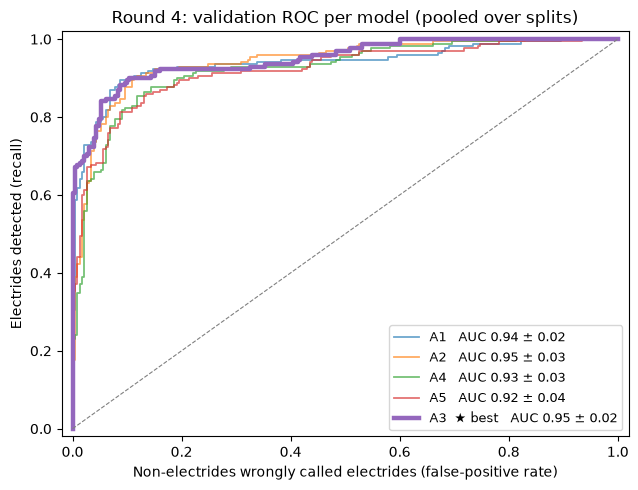

Best feature set in round 4: A3 | ROC-AUC 0.95 ± 0.02 | F1 0.88 ± 0.03 | pauling_electronegativity__mean  40%, space_group__number  15%, pauling_electronegativity__std  14%, sampled_grid_clearance_statistics_A__mean  13%, volume_per_atom_A3  8%, total_assignment_count  6%, alkali_alkaline_site_fraction  3%, f_block_site_fraction  1%

==================== ROUND 5/5 ====================
finished: A1 A2 A5 A3 A4 


Agent,Peers,Tool,Evidence,Feature set,Share of the model's decisions,F1,ROC-AUC,Electrides found / non-electrides rejected,Notes,Tokens in / out
A1,"A5, A3",-,-,pauling_electronegativity__mean pauling_electronegativity__min alkali_alkaline_site_fraction f_block_site_fraction sampled_grid_clearance_statistics_A__mean max_clearance_A total_assignment_count space_group__number,pauling_electronegativity__mean 42% space_group__number 19% sampled_grid_clearance_statistics_A__mean 14% total_assignment_count 8% max_clearance_A 7% alkali_alkaline_site_fraction 3% pauling_electronegativity__min 3% f_block_site_fraction 3%,0.88 ± 0.03,0.95 ± 0.01,0.88 / 0.90,no clear change vs parent #10 (+0.000),"29,854 / 2,065"
A2,"A5, A3",-,-,pauling_electronegativity__mean pauling_electronegativity__std sampled_grid_clearance_statistics_A__mean max_clearance_A volume_per_atom_A3 total_assignment_count space_group__number candidate_count_before_output_limit,pauling_electronegativity__mean 41% space_group__number 14% pauling_electronegativity__std 13% sampled_grid_clearance_statistics_A__mean 13% volume_per_atom_A3 6% total_assignment_count 5% max_clearance_A 4% candidate_count_before_output_limit 4%,0.87 ± 0.02,0.94 ± 0.02,0.87 / 0.90,worse vs parent #13 (-0.006),"30,727 / 1,793"
A3,"A5, A4",-,-,pauling_electronegativity__mean pauling_electronegativity__std pauling_electronegativity__min sampled_grid_clearance_statistics_A__mean sampled_grid_clearance_statistics_A__std volume_per_atom_A3 candidate_count_before_output_limit space_group__number,pauling_electronegativity__mean 41% space_group__number 15% pauling_electronegativity__std 14% sampled_grid_clearance_statistics_A__mean 13% volume_per_atom_A3 6% candidate_count_before_output_limit 4% sampled_grid_clearance_statistics_A__std 4% pauling_electronegativity__min 3%,0.86 ± 0.06,0.94 ± 0.02,0.87 / 0.89,worse vs parent #20 (-0.013),"29,711 / 1,700"
A4,"A5, A3",-,-,pauling_electronegativity__mean pauling_electronegativity__std sampled_grid_clearance_statistics_A__mean max_clearance_A total_assignment_count space_group__number transition_metal_site_fraction candidate_count_before_output_limit,pauling_electronegativity__mean 41% space_group__number 14% sampled_grid_clearance_statistics_A__mean 13% pauling_electronegativity__std 13% total_assignment_count 6% max_clearance_A 5% candidate_count_before_output_limit 5% transition_metal_site_fraction 2%,0.89 ± 0.03,0.96 ± 0.01,0.88 / 0.92,no clear change vs parent #12 (-0.002),"30,808 / 1,992"
A5,"A4, A3",-,-,pauling_electronegativity__mean sampled_grid_clearance_statistics_A__mean max_clearance_A alkali_alkaline_site_fraction f_block_site_fraction candidate_count_before_output_limit volume_per_atom_A3 pauling_electronegativity__min,pauling_electronegativity__mean 43% sampled_grid_clearance_statistics_A__mean 18% max_clearance_A 11% alkali_alkaline_site_fraction 8% candidate_count_before_output_limit 7% volume_per_atom_A3 6% pauling_electronegativity__min 4% f_block_site_fraction 4%,0.83 ± 0.02,0.92 ± 0.04,0.81 / 0.90,same model as #17 worse vs parent #15 (-0.031),"30,127 / 1,654"


Agent,Answer,Next step,Suggested new features
A1,"The evaluation of the previous round showed that the strongest contributors are the mean Pauling electronegativity, its spread, the mean sampled‑grid clearance and the space‑group number. Features that were weak (candidate_count_before_output_limit, alkali_alkaline_site_fraction, f_block_site_fraction, volume_per_atom_A3) can be replaced by descriptors that capture complementary aspects of the three electride pillars: (i) electropositivity (both ...","Submit this revised eight‑feature set for deterministic evaluation. If ROC‑AUC improves, analyse the feature‑importance; if any descriptor remains weak, consider swapping max_clearance_A for candidate_count_before_output_limit or adding an interacti","• electron_localization_function_max: maximum ELF value within identified interstitial basins – would directly quantify anionic electron confinement. • void_connectivity_dimensionality: categorical descriptor (0D/1D/2D) of the void network topology – distinguishes cavity, channel, and layer electrides."
A2,"The most informative descriptors identified so far are the average Pauling electronegativity, its spread, and the mean sampled‑grid clearance – together they capture the electropositive chemistry and the overall openness of the lattice. Features that contributed little in the latest model (alkali_alkaline_site_fraction, f_block_site_fraction, metal_site_fraction, candidate_count_before_output_limit) are therefore removed. To strengthen the thre ...","Submit the revised eight‑feature set for deterministic evaluation to see whether ROC‑AUC exceeds the current best (~0.95). If performance plateaus, I will explore interaction terms (e.g., pauling_electronegativity__mean × max_clearance_A) or derived",• electron_localization_function_max: maximum ELF value within identified void regions – directly quantifies anionic electron confinement. • void_connectivity_dimensionality: categorical descriptor (0D/1D/2D) describing the topology of the void network.
A3,"The evaluation shows that the most discriminating descriptors are the average and spread of electronegativity, the minimum electronegativity (capturing the most electro‑positive element), the mean sampled‑grid clearance, and the space‑group number (which encodes cage/channel symmetries). Features that contributed little (alkali_alkaline_site_fraction, f_block_site_fraction, volume_per_atom_A3, total_assignment_count) should be replaced with descr ...","Submit the revised eight‑feature set for deterministic evaluation. If the ROC‑AUC does not improve, consider adding an interaction term (e.g., pauling_electronegativity__min × candidate_count_before_output_limit) or a derived ratio such as candidate","• ELF_max_in_voids – maximum electron‑localisation‑function value within identified void regions (direct quantification of anionic electron density). • void_connectivity_dimensionality – categorical descriptor (0D, 1D, 2D) describing the topology of the void network."
A4,"The high‑throughput electride screening studies (Xiao et al., arXiv:2605.11724) show that a useful figure‑of‑merit combines (i) a globally electropositive and chemically heterogeneous composition, (ii) a charge‑balance ambiguity that forces excess electrons into the lattice, and (iii) a spacious, heterogeneous interstitial network. The previous best model (ROC‑AUC 0.96) used mean and std electronegativity, mean clearance, max clearance, total ox ...","Submit the eight‑feature set for deterministic evaluation to see whether ROC‑AUC surpasses the previous 0.96. If performance plateaus, consider deriving a ratio such as `candidate_count_before_output_limit / volume_per_atom_A3` (once volume per atom","• ELF_max_in_voids – maximum electron localization function value within identified void regions to directly quantify anionic electron density. • Void_connectivity_dimensionality – categorical descriptor (0D, 1D, 2D) describing the topology of the void network."
A5,"The evaluati

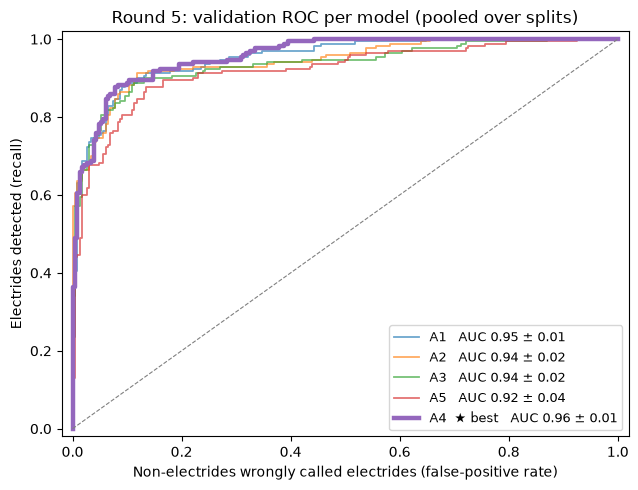

Best feature set in round 5: A4 | ROC-AUC 0.96 ± 0.01 | F1 0.89 ± 0.03 | pauling_electronegativity__mean  41%, space_group__number  14%, sampled_grid_clearance_statistics_A__mean  13%, pauling_electronegativity__std  13%, total_assignment_count  6%, max_clearance_A  5%, candidate_count_before_output_limit  5%, transition_metal_site_fraction  2%


Rank,,#,Agent,Round,Features,F1,ROC-AUC,Electrides found / non-electrides rejected,Feature set (share of the model's decisions)
1,★,12,A4,3,7,0.89 ± 0.03,0.96 ± 0.01,0.88 / 0.93,pauling_electronegativity__mean 43% space_group__number 14% sampled_grid_clearance_statistics_A__mean 14% pauling_electronegativity__std 14% max_clearance_A 7% total_assignment_count 6% transition_metal_site_fraction 2%
2,,25,A4,5,8,0.89 ± 0.03,0.96 ± 0.01,0.88 / 0.92,pauling_electronegativity__mean 41% space_group__number 14% sampled_grid_clearance_statistics_A__mean 13% pauling_electronegativity__std 13% total_assignment_count 6% max_clearance_A 5% candidate_count_before_output_limit 5% transition_metal_site_fraction 2%
3,,15,A5,3,8,0.86 ± 0.03,0.95 ± 0.02,0.85 / 0.90,pauling_electronegativity__mean 41% space_group__number 14% sampled_grid_clearance_statistics_A__mean 14% pauling_electronegativity__std 13% total_assignment_count 6% sampled_grid_clearance_statistics_A__std 5% metal_site_fraction 3% transition_metal_site_fraction 3%
4,,21,A1,5,8,0.88 ± 0.03,0.95 ± 0.01,0.88 / 0.90,pauling_electronegativity__mean 42% space_group__number 19% sampled_grid_clearance_statistics_A__mean 14% total_assignment_count 8% max_clearance_A 7% alkali_alkaline_site_fraction 3% pauling_electronegativity__min 3% f_block_site_fraction 3%
5,,20,A3,4,8,0.88 ± 0.03,0.95 ± 0.02,0.89 / 0.90,pauling_electronegativity__mean 40% space_group__number 15% pauling_electronegativity__std 14% sampled_grid_clearance_statistics_A__mean 13% volume_per_atom_A3 8% total_assignment_count 6% alkali_alkaline_site_fraction 3% f_block_site_fraction 1%
6,,13,A2,3,8,0.88 ± 0.03,0.95 ± 0.01,0.88 / 0.91,pauling_electronegativity__mean 40% space_group__number 14% pauling_electronegativity__std 14% sampled_grid_clearance_statistics_A__mean 13% volume_per_atom_A3 7% total_assignment_count 6% alkali_alkaline_site_fraction 3% transition_metal_site_fraction 2%
7,,18,A2,4,8,0.87 ± 0.05,0.95 ± 0.03,0.88 / 0.90,pauling_electronegativity__mean 43% sampled_grid_clearance_statistics_A__mean 17% pauling_electronegativity__std 16% sampled_grid_clearance_statistics_A__max 7% candidate_count_before_output_limit 7% alkali_alkaline_site_fraction 5% metal_site_fraction 3% f_block_site_fraction 2%
8,,22,A2,5,8,0.87 ± 0.02,0.94 ± 0.02,0.87 / 0.90,pauling_electronegativity__mean 41% space_group__number 14% pauling_electronegativity__std 13% sampled_grid_clearance_statistics_A__mean 13% volume_per_atom_A3 6% total_assignment_count 5% max_clearance_A 4% candidate_count_before_output_limit 4%


Item,Value
Model,"#12 (A4, round 3)"
Ranked first by,highest validation ROC-AUC (mean over 5 splits)
Fitted on all 200 structures,"gradient boosting on 7 features (n_estimators=200, learning_rate=0.05, max_depth=3, subsample=0.9)"
structure_summary.pauling_electronegativity__mean,share of the model's decisions 45%
structure_summary.space_group__number,share of the model's decisions 18%
structure_summary.pauling_electronegativity__std,share of the model's decisions 12%
cavity_geometry.sampled_grid_clearance_statistics_A__mean,share of the model's decisions 11%
cavity_geometry.max_clearance_A,share of the model's decisions 7%
electron_count_hypotheses.total_assignment_count,share of the model's decisions 6%
structure_summary.transition_metal_site_fraction,share of the model's decisions 2%


Suggested new feature,Times suggested,"By (agent, round)",Description (first seen)
Void connectivity dimensionality,20,"A1 R1, A3 R1, A5 R1, A5 R2, A3 R2, A4 R2, A1 R2, A1 R3, A4 R3, A3 R3, A5 R3, A1 R4, A5 R4, A4 R4, A3 R4, A1 R5, A2 R5, A5 R5, A3 R5, A4 R5","Void connectivity dimensionality (0D/1D/2D) – distinguishes cavity, channel, and layer electrides."
Electron localization function,9,"A4 R1, A2 R1, A1 R1, A4 R2, A2 R2, A1 R2, A1 R3, A2 R3, A2 R4",Electron localization function (ELF) peak values in interstitial regions to directly quantify electron confinement.
ELF_max_in_voids,9,"A3 R1, A3 R2, A4 R3, A3 R3, A4 R4, A3 R4, A5 R5, A3 R5, A4 R5",ELF_max_in_voids – maximum electron localization function value within identified void regions to directly capture interstitial electron density.
electron_localization_function_max,7,"A5 R1, A5 R2, A5 R3, A1 R4, A5 R4, A1 R5, A2 R5",electron_localization_function_max: maximum ELF value in interstitial regions to directly quantify electron confinement
Bader_charge_void,3,"A3 R1, A3 R2, A3 R3","Bader_charge_void – Bader charge integrated over void sites, quantifying anionic electron population."
Void‑network dimensionality,3,"A2 R2, A2 R3, A2 R4",Void‑network dimensionality (0D/1D/2D) derived from a graph of void centers.
Void connectivity metrics,2,"A4 R1, A2 R1","Void connectivity metrics (e.g., dimensionality of the void network) to distinguish 0D cavities from 1D/2D channels."
Average distance between interstitial void centers and nearest cation to assess,1,A4 R1,Average distance between interstitial void centers and nearest cation to assess stabilization of anionic electrons.
Average distance between void centers and nearest electropositive cation to asse,1,A2 R2,Average distance between void centers and nearest electropositive cation to assess stabilization of interstitial electrons.
Bader charge on identified void centers,1,A1 R1,Bader charge on identified void centers – provides a charge‑based measure of electron localization.


Agent,calls,prompt,completion,reasoning
A1,11,147427,16383,5566
A2,10,148907,15564,5314
A3,11,155670,15359,4372
A4,10,149727,15990,4936
A5,12,153351,17326,4743
TOTAL,54,755082,80622,24931


In [6]:
last_round, results = await swarm.run()

## 5. Analysis of the run

All plots come from the evaluations the swarm already did (`swarm.evaluator.history`), so nothing is refitted.

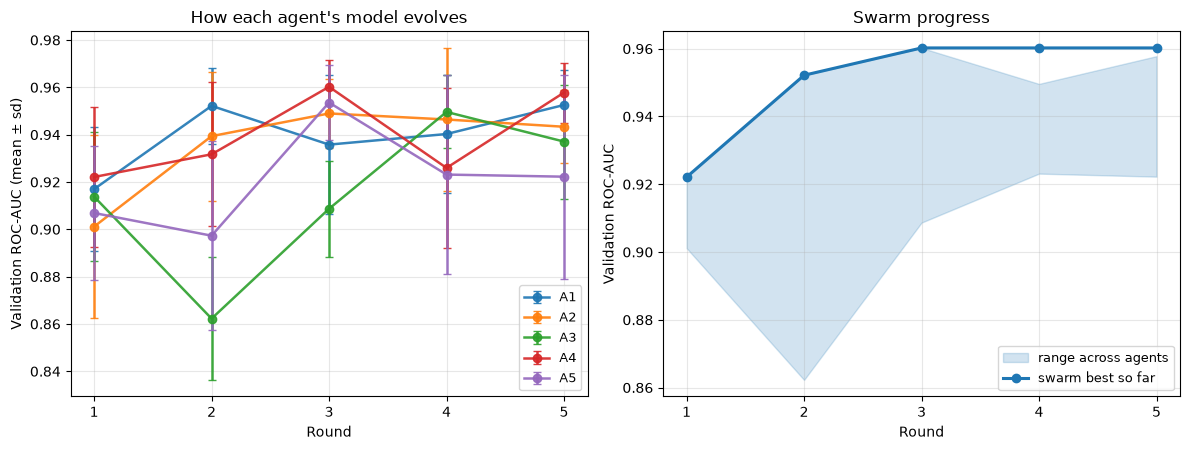

,Agent,Round,Features,roc_auc,± sd,vs parent
0,A1,1,8,0.917,0.026,first
1,A1,2,8,0.952,0.016,improved
2,A1,3,8,0.936,0.029,worse
3,A1,4,8,0.940,0.025,worse
4,A1,5,8,0.953,0.015,no clear change
5,A2,1,8,0.901,0.039,first
6,A2,2,8,0.939,0.027,improved
7,A2,3,8,0.949,0.015,improved
8,A2,4,8,0.946,0.030,no clear change
9,A2,5,8,0.943,0.015,worse


In [7]:
import analysis

# How each agent's score evolves, and the swarm's best-so-far
progress = analysis.plot_agent_progress(swarm)
progress

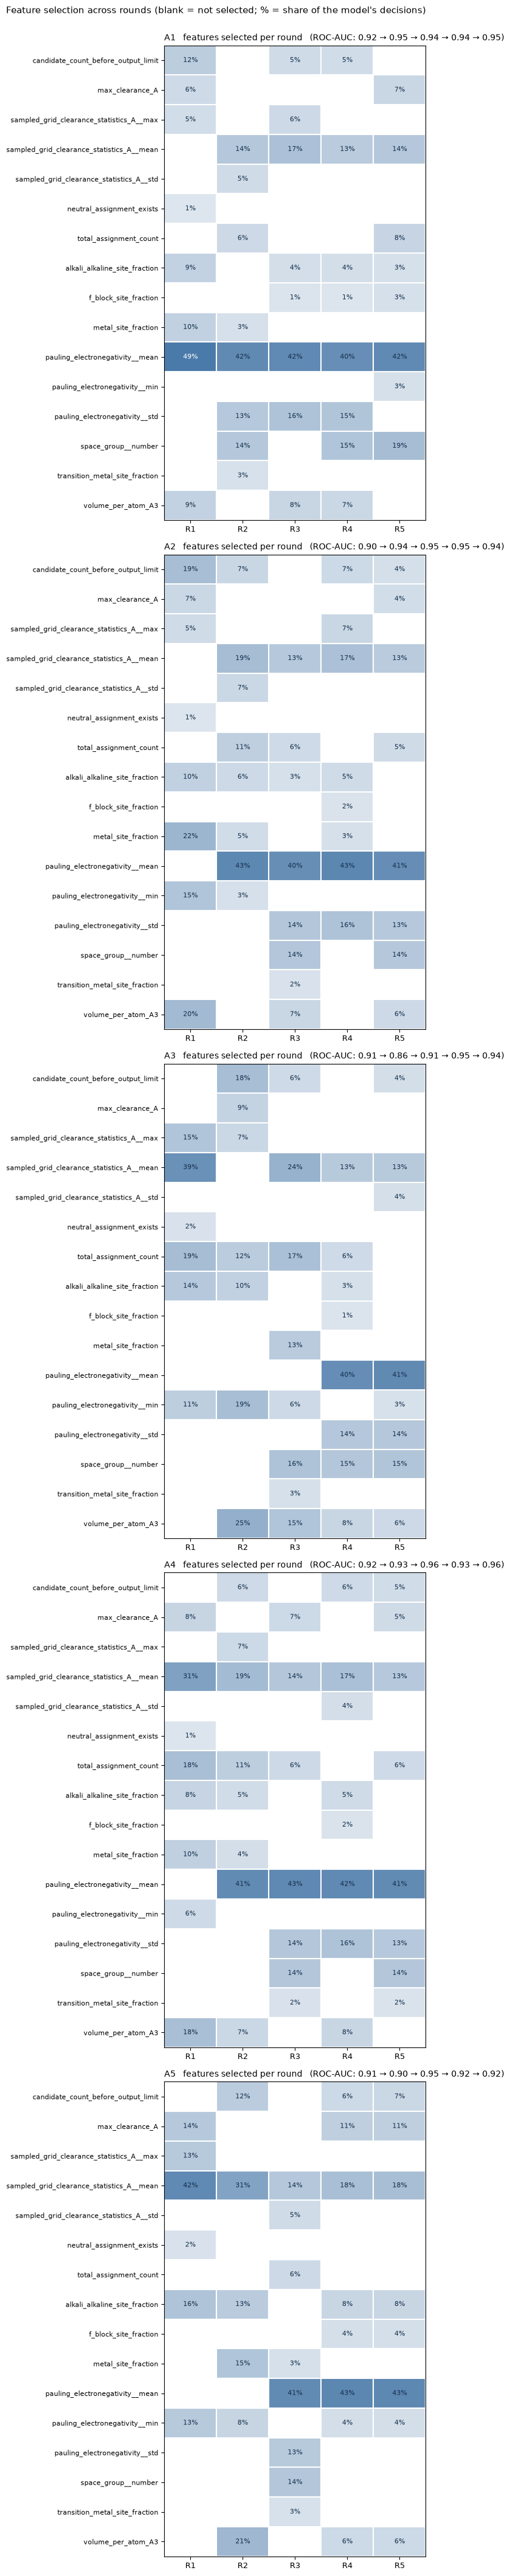

In [8]:
# Which features each agent selected in each round (% = share of that round's fitted model decisions)
analysis.plot_feature_map(swarm)

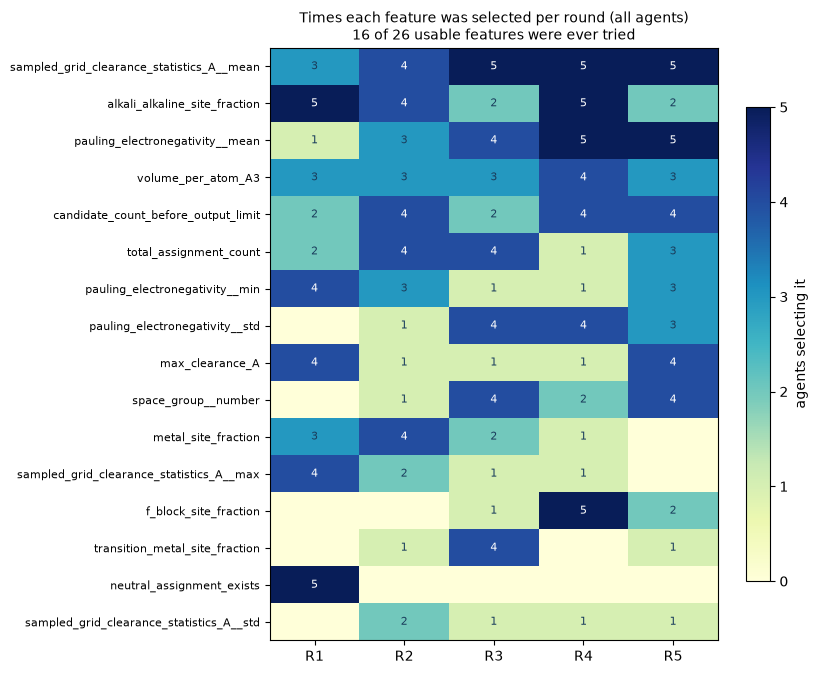

In [9]:
# How often each feature was selected per round, across all agents
analysis.plot_feature_usage(swarm)

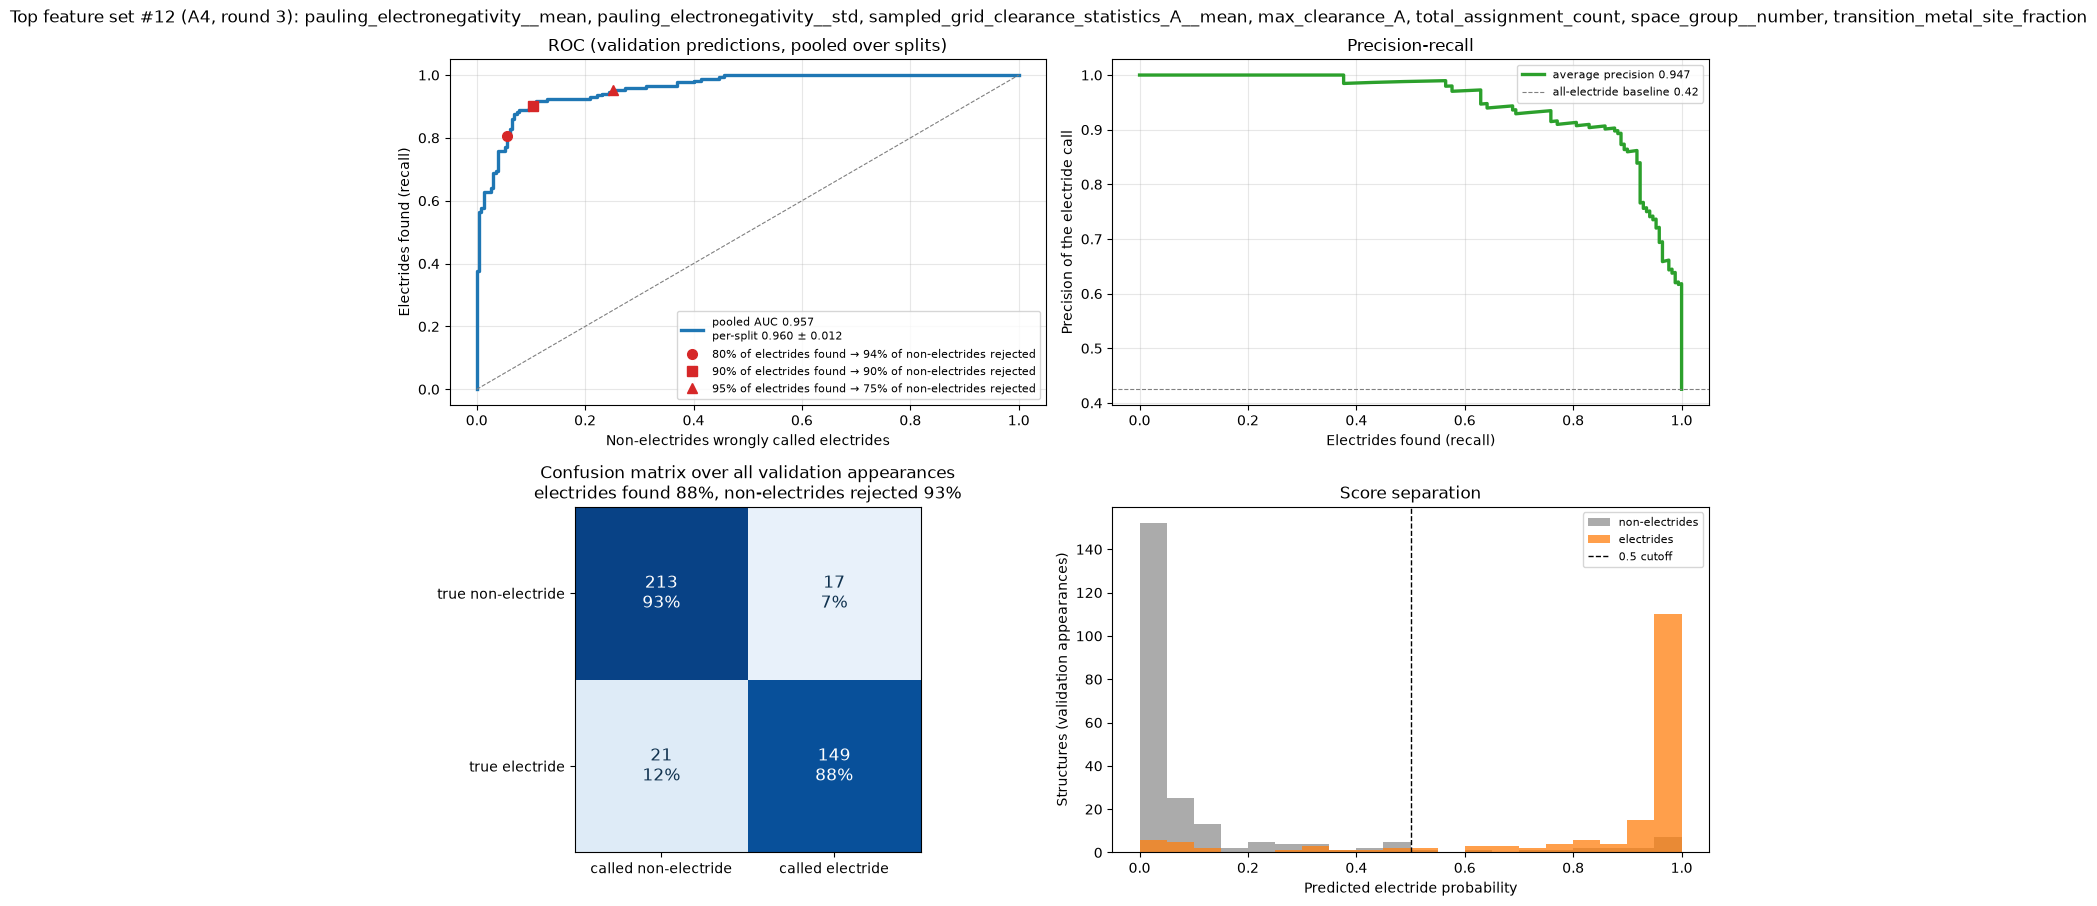

,Metric,Mean over splits,± sd
0,roc auc,0.960,0.012
1,f1,0.887,0.025
2,accuracy,0.905,0.020
3,precision,0.900,0.037
4,recall,0.876,0.047
5,specificity,0.926,0.029


In [10]:
# Classification metrics of the top-ranked feature set (validation predictions pooled over the splits)
metrics = analysis.plot_final_model(swarm, results)
metrics

## 6. Structure viewer

Pass the CIF paths of one electride and one non-electride. `pick_example_structures` finds the most confidently predicted example of each class and its CIF under `cif_dir`; otherwise give the two paths yourself. Use `repeat=(2, 2, 1)` to tile the cell and `rotations=` for other orientations.

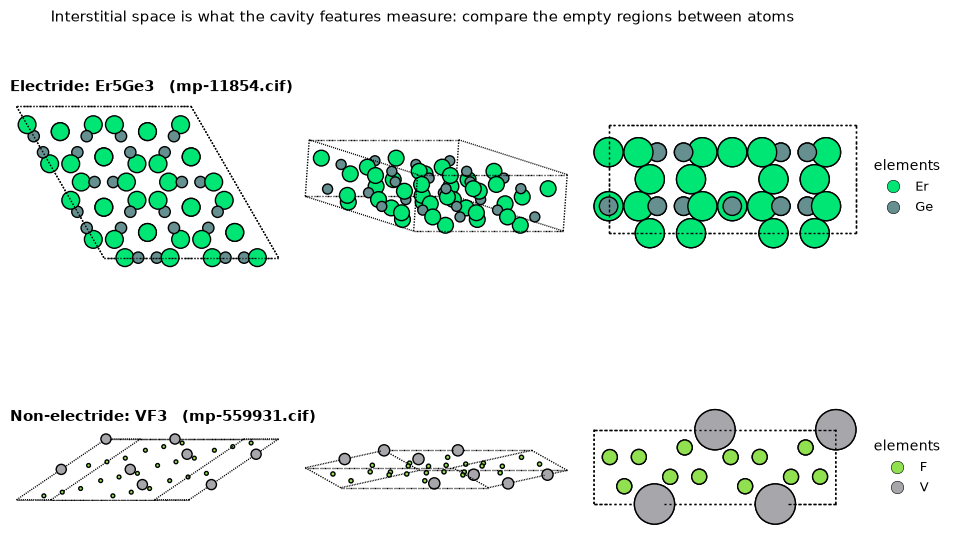

In [11]:
# Option A: let the top model pick the clearest example of each class (needs CIFs in cif_dir)
# el_cif, non_cif, probability = analysis.pick_example_structures(swarm, results, cif_dir="structures")

# Option B: your own two files
el_cif, non_cif, probability = "data/data_extract/structures/mp-11854.cif", "data/data_extract/structures/mp-559931.cif", None

analysis.show_structures(el_cif, non_cif, repeat=(2, 2, 1), probability=probability)

## 7. Score a dataset with the final model

Swap `DATA_CSV` for your separate dataset (labels optional). In a new session use `score_dataset(None, ...)` for the newest `outputs/final_model_*.joblib`, or pass its path.

In [12]:
DATA_CSV = CONFIG["data"]["dataset_csv"]
scores, score_metrics = score_dataset(results["final_fit"], DATA_CSV, out_csv="outputs/final_model_scores.csv")
scores.sort_values("probability", ascending=False)

Model from outputs/final_model_2026-10-22_173111.joblib:
  features: structure_summary.pauling_electronegativity__mean, structure_summary.pauling_electronegativity__std, cavity_geometry.sampled_grid_clearance_statistics_A__mean, cavity_geometry.max_clearance_A, electron_count_hypotheses.total_assignment_count, structure_summary.space_group__number, structure_summary.transition_metal_site_fraction
  electron_count_hypotheses__total_assignment_count: 7 missing -> training median 4
Metrics: {'n': 200, 'electrides': 84, 'accuracy': 1.0, 'precision': 1.0, 'recall': 1.0, 'specificity': 1.0, 'f1': 1.0, 'roc_auc': 1.0}
Confusion matrix [[TN, FP], [FN, TP]]: [[116, 0], [0, 84]]
Saved 200 scores to outputs/final_model_scores.csv


/Users/z8i/anaconda3/lib/python3.13/site-packages/sklearn/utils/validation.py:2749: UserWarning: X does not have valid feature names, but SimpleImputer was fitted with feature names
  warnings.warn(


,structure,probability,predicted,label
69,mp-1105908.cif,0.998336,1,1
172,mp-605860.cif,0.997933,1,1
132,mp-1464.cif,0.997850,1,1
197,mp-9909.cif,0.997833,1,1
161,mp-510503.cif,0.997731,1,1
...,...,...,...,...
64,mp-1078845.cif,0.001053,0,0
199,mp-999263.cif,0.001022,0,0
76,mp-1180981.cif,0.000998,0,0
106,mp-1216192.cif,0.000886,0,0
